# Final report



In [ ]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
from scipy.optimize import curve_fit
import pandas as pd
import seaborn as sns
from tqdm import trange
from itertools import product
import openpyxl
from sklearn.cluster import KMeans



## 1. Naka–Rushton 

Fixing Hill exponents from Elisa

In [8]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


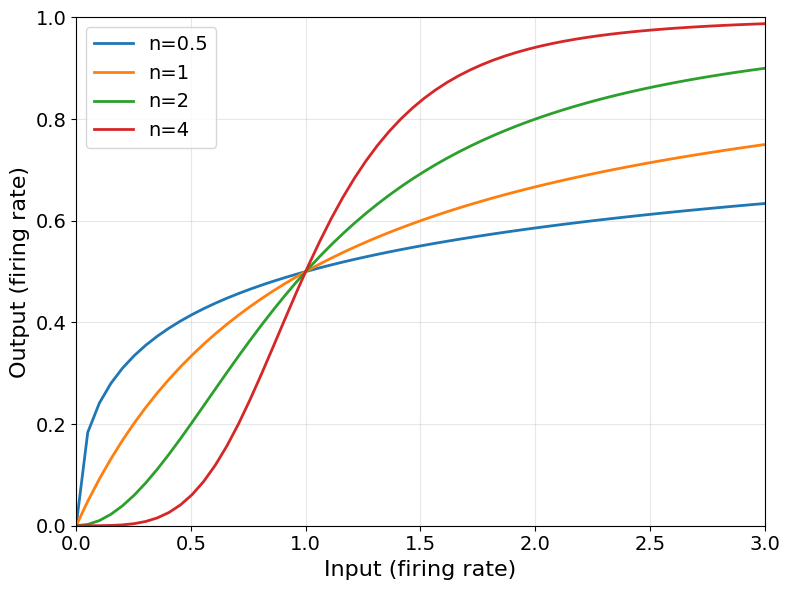

In [7]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [0.5, 1, 2, 4]

plt.figure(figsize=(8, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=16)
plt.ylabel('Output (firing rate)', fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
plt.tick_params(axis='both', direction='out', labelsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.savefig(f'Figures_final/naka_rushton_og.eps')
plt.show()

In [10]:
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

## 2. Symmetric weight



In [9]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

## 3. Random initialisations and Adam optimisation to hit output targets

- draw many initial `theta`
- minimise a squared-error loss on target firing rates
- keep converged solutions

In [12]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

# target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # mitral cell output
g_target = jnp.array([0.5, 0.5])  # green neurons
b_target = jnp.array([0.5, 0.5])  # blue neurons
r_target = jnp.array([0.5, 0.5])  # red neurons

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y
no_params = 12  # total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g={n_g}, n_y={n_y}")

Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 12
  - Target firing rates: [0.5 0.5]
  - Input signal: [1. 1.]
  - N values: n_r=1.85, n_b=0.642, n_g=1.868, n_y=1.562


## 4. Load params, test stability 



In [ ]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_626_final.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (626, 12)
Number of samples: 626
Number of parameters per sample: 12


In [39]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [40]:
# Analyse all converged samples (626)
n_samples_to_analyze = theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"Using {n_samples_to_analyze} samples for stability")


Using 626 samples for stability


In [41]:
# Analyze stability

stability_results_all = {}

n_r = 2.333
n_b = 0.9
n_g = 2.0626
n_y = 1.562


stability_results = []
max_real_parts = []
min_real_parts = []
all_eigenvalues = []

for i in range(n_samples_to_analyze):
    theta_star = theta_subset[i, :]

    # Get fixed point outputs with new n values
    try:
        r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)

        # Construct state vector s* = [r, g, y]
        s_star = jnp.concatenate([r_star, g_star, y_star])

        # Verify it's a fixed point
        s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
        s_error = jnp.linalg.norm(s_prime - s_star)

        if s_error > 1e-3:
            print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

        # Compute stability
        result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
        stability_results.append(result)

        max_real_parts.append(np.max(result['real_parts']))
        min_real_parts.append(np.min(result['real_parts']))
        all_eigenvalues.append(result['eigenvalues'])

    except Exception as e:
        print(f"  Sample {i+1}: Error - {e}")
        continue


KeyboardInterrupt: 

In [ ]:
# remove unstable theta
theta_opt = np.array(theta_opt)

# Identify unstable samples from stability_results
remove_row = [i for i, r in enumerate(stability_results) if not r['is_stable']]

max_index = theta_opt.shape[0] - 1
valid_remove_row = [i for i in remove_row if 0 <= i <= max_index]

for i in sorted(valid_remove_row, reverse=True):
    theta_opt = np.delete(theta_opt, i, axis=0)

In [ ]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


## 6. Output Hessian and eigenvalue spectra

We scalarise the readout with `sum(y)` and compute the Hessian \(H=\nabla^2(\sum y)\). Eigenvalues are sorted by magnitude; **four** are consistently much smaller than the rest — a near-null “soft” subspace.


# Compute Hessian

Processing 626 samples...
  Sample 1/626...
  Sample 101/626...
  Sample 201/626...
  Sample 301/626...
  Sample 401/626...
  Sample 501/626...
  Sample 601/626...
Completed processing 626 samples


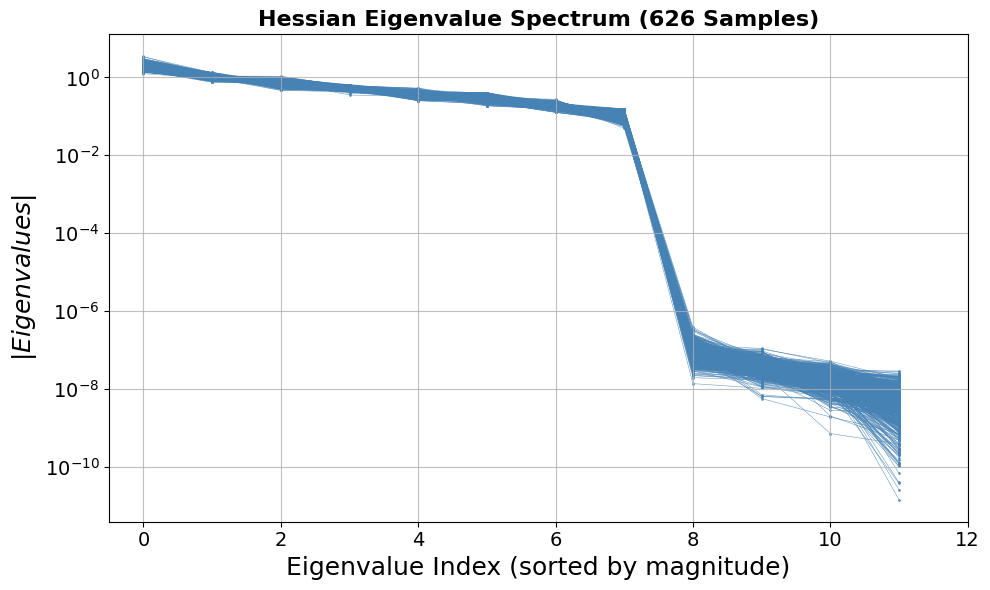

In [42]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [43]:

threshold = 1e-5  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)

    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)

    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)

    return eigenvectors_subspace2

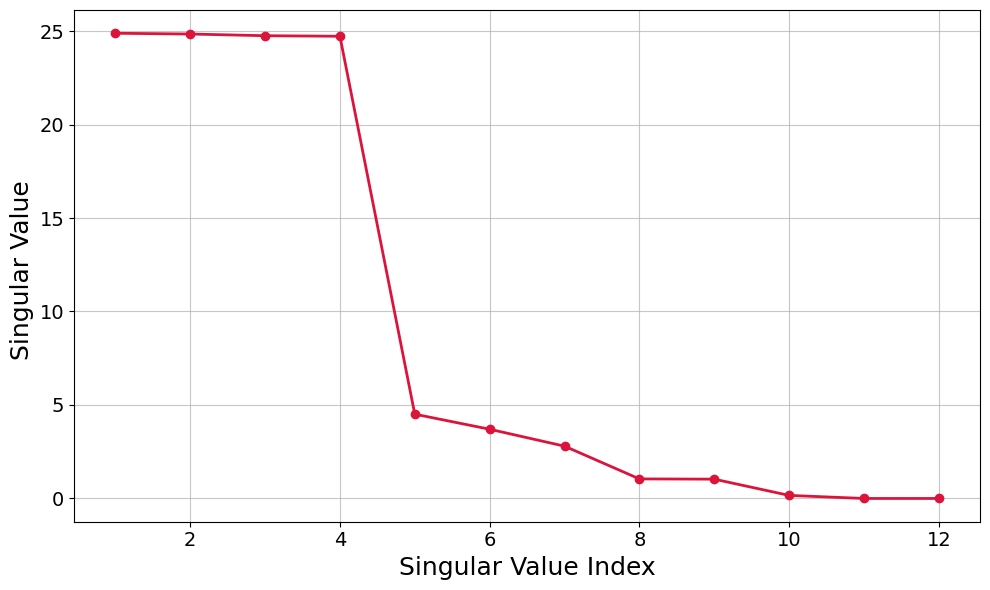

In [44]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(S)+1), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=18)
plt.ylabel('Singular Value ', fontsize=18)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

In [45]:
Vt[:4].shape # orthonormal rows
Vt[:4].T.shape # orthonormal columns

(12, 4)

## 7. Concatenate near-null eigenvectors, SVD, then find sparse rotation


In [46]:
def sparse_rotation(U):

    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))


    # Initialise Adam optimizer
    key = jax.random.PRNGKey(0)
    key, subkey = jax.random.split(key)
    k = U.shape[1]  # Number of columns
    qtilde = jax.random.normal(subkey, (k, k))  # Fixed: should be (k, k) not (r, k)
    optimizer = optax.adam(learning_rate=0.004, eps=1e-4)
    opt_state = optimizer.init(qtilde)


    # Create value_and_grad function
    loss_value_and_grad = jax.value_and_grad(loss)

    # Optimization loop
    for iteration in range(10000):
        loss_value, grads = loss_value_and_grad(qtilde)
        updates, opt_state = optimizer.update(grads, opt_state)
        qtilde = optax.apply_updates(qtilde, updates)

        if iteration % 1000 == 0:
            print(f"Iteration {iteration}, Loss: {float(loss_value)}")

    # Get optimized q
    q_opt,_ = jnp.linalg.qr(qtilde)

    U_sparse = U @ q_opt
    return U_sparse

#U_sparse = sparse_rotation(Vt[:4].T)

In [47]:
def varimax(U, iterations=1000, tol=1e-8):
    n, k = U.shape
    # Initialize Q as an identity matrix
    Q = np.eye(k)
    
    # Optional: Normalizing U (Kaiser Normalization)
    row_norms = np.sqrt(np.sum(U**2, axis=1, keepdims=True))
    U_norm = U / row_norms

    for i in range(iterations):
        Q_old = Q.copy()
        
        # 1. Rotate the basis: U_tilde = U @ Q
        U_tilde = U_norm @ Q
        
        # 2. Compute the Varimax objective gradient
        # (U_tilde**3) is the derivative of the L4 norm (sum of squared variances)
        A = U_norm.T @ (U_tilde**3 - (1.0/n) * U_tilde @ np.diag(np.sum(U_tilde**2, axis=0)))
        
        # 3. Use SVD to find the nearest orthogonal matrix (Procrustes Step)
        L, S, M_h = np.linalg.svd(A)
        Q = L @ M_h
        
        # Check convergence
        if np.abs(np.abs(np.diag(Q @ Q_old.T)).sum() - k) < tol:
            break

    # Final sparse representation
    U_sparse = (U_norm @ Q) * row_norms
    return U_sparse, Q

#U_sparse, Q = varimax(Vt[:4].T)

In [48]:
U_1, Q = varimax(Vt[:4].T)
U_2 = sparse_rotation(Vt[:4].T)

Iteration 0, Loss: 0.20072558522224426
Iteration 1000, Loss: 0.1548072099685669
Iteration 2000, Loss: 0.1548178791999817
Iteration 3000, Loss: 0.15481486916542053
Iteration 4000, Loss: 0.15488168597221375
Iteration 5000, Loss: 0.15481367707252502
Iteration 6000, Loss: 0.15484249591827393
Iteration 7000, Loss: 0.15479782223701477
Iteration 8000, Loss: 0.154798686504364
Iteration 9000, Loss: 0.15480616688728333


In [49]:
basis_prod = U_1.T @ U_2
basis_prod.shape

(4, 4)

In [50]:
U_svd, S_svd, Vt_svd = np.linalg.svd(basis_prod)
S_svd


array([1.0000004 , 1.0000001 , 1.        , 0.99999994], dtype=float32)

In [51]:
U_sparse = U_1

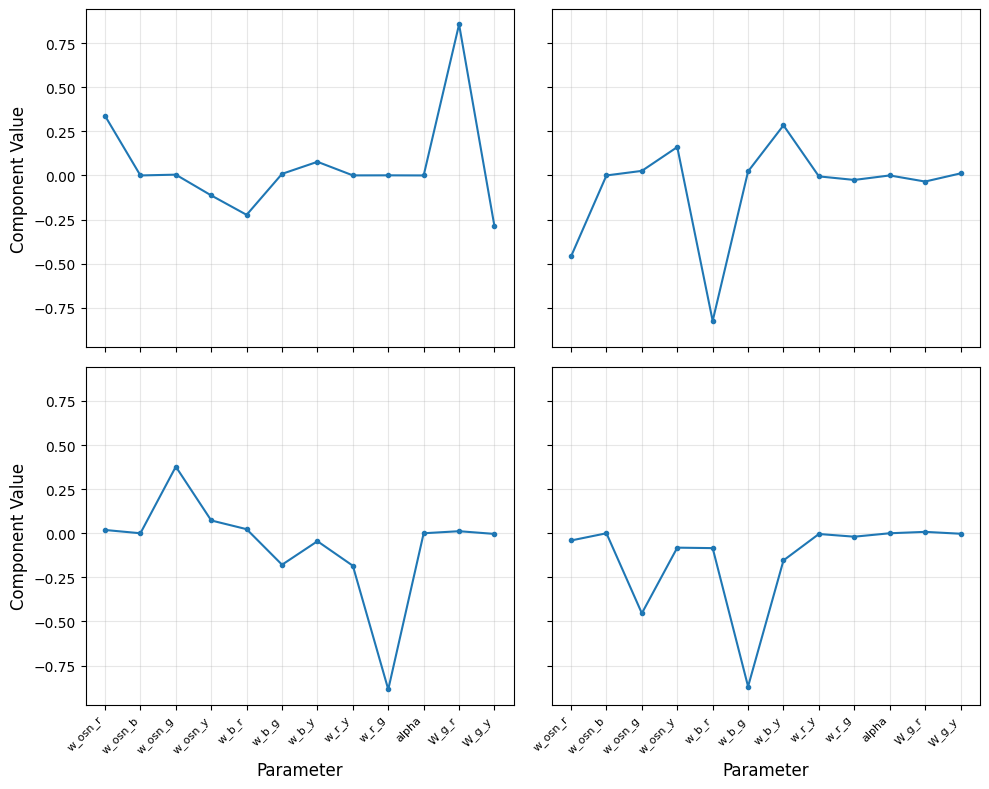

In [52]:

M = U_sparse

# Create parameter labels in the correct order
param_labels = [
    'w_osn_r',
    'w_osn_b',
    'w_osn_g',
    'w_osn_y',
    'w_b_r',
    'w_b_g',
    'w_b_y',
    'w_r_y',
    'w_r_g',
    'alpha',
    'W_g_r',
    'W_g_y'
]

# Sort components by sparsity (sum of absolute values)
M_sums = np.abs(M).sum(0)
sorting_ind = np.argsort(M_sums)[::-1]
M_plot = M[:, sorting_ind]

# Get number of components
n_components = M_plot.shape[1]

# Calculate grid size
n_rows, n_cols = 2, 2
fig, ax = plt.subplots(figsize=(10, 8), nrows=n_rows, ncols=n_cols, sharex=True, sharey=True)

# Flatten axes array for easier indexing
ax = ax.flatten()

# Plot all components
for i in range(n_components):
    ax[i].plot(M_plot[:, i], '.-', label=f'Component {sorting_ind[i]+1} (sorted {i+1})')
    ax[i].set_xticks(range(len(param_labels)))
    ax[i].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    ax[i].grid(True, alpha=0.3)


# Hide unused subplots
for i in range(n_components, n_rows * n_cols):
    ax[i].axis('off')

# Set labels for bottom row
for col in range(n_cols):
    row_idx = (n_rows - 1) * n_cols + col
    if row_idx < n_components:
        ax[row_idx].set_xlabel('Parameter', fontsize=12)

# Set labels for left column
for row in range(n_rows):
    col_idx = row * n_cols
    if col_idx < n_components:
        ax[col_idx].set_ylabel('Component Value', fontsize=12)

plt.tight_layout()
plt.show()

## 8. Many random orthogonal initialisations for L1 rotation

Because `sparse_rotation` is non-convex, we ran **10 000** random seeds, histogrammed the terminal L1 loss, saw **three** major peaks, zoomed into the **lowest** peak, then found **two** sub-peaks corresponding to **two families** of sparse bases (each essentially a signed permutation of four “canonical” directions).


In [ ]:
def sparse_rotation(
    U, key, use_scheduler=True, scheduler_type='plateau', verbose=True
):

    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))


    # Initialise Adam optimizer with learning rate scheduler
    key = jax.random.PRNGKey(key)
    key, subkey = jax.random.split(key)
    k = U.shape[1]  # Number of columns
    qtilde = jax.random.normal(subkey, (k, k))  # Fixed: should be (k, k) not (r, k)
    
    # Set up learning rate schedule
    if use_scheduler:
        if scheduler_type == 'cosine':
            # Cosine decay: more gradual reduction, keeps LR high for longer
            schedule = optax.cosine_decay_schedule(
                init_value=0.01,
                decay_steps=10000,  # Full decay over all iterations
                alpha=0.1  # Final LR will be 0.01 * 0.1 = 0.001
            )
            optimizer = optax.chain(
                optax.scale_by_adam(eps=1e-4),
                optax.scale_by_schedule(schedule)
            )
        elif scheduler_type == 'step':
            # Step decay: reduce LR at specific milestones (much later)
            schedule = optax.piecewise_constant_schedule(
                init_value=0.01,
                boundaries_and_scales={5000: 0.5, 8000: 0.5}  # Reduce by 0.5x at 5000 and 8000
            )
            optimizer = optax.chain(
                optax.scale_by_adam(eps=1e-4),
                optax.scale_by_schedule(schedule)
            )
        else:  # 'plateau' - reduce LR when loss plateaus
            # Start with fixed LR, will adjust manually
            schedule = None
            optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
    else:
        schedule = None
        optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
    
    opt_state = optimizer.init(qtilde)

    # Create value_and_grad function
    loss_value_and_grad = jax.value_and_grad(loss)

    # Track loss history
    loss_history = []
    n_iterations = 10000
    
    # For plateau scheduler: track best loss and patience
    if use_scheduler and scheduler_type == 'plateau':
        best_loss = float('inf')
        patience = 2000  # Wait 2000 iterations before reducing LR
        patience_counter = 0
        current_lr = 0.01
        lr_reduction_factor = 0.5
        min_lr = 0.0001

    # Optimization loop
    for iteration in range(n_iterations):
        loss_value, grads = loss_value_and_grad(qtilde)
        
        # For plateau scheduler: check if we should reduce LR
        if use_scheduler and scheduler_type == 'plateau':
            if loss_value < best_loss:
                best_loss = float(loss_value)
                patience_counter = 0
            else:
                patience_counter += 1
                
            if patience_counter >= patience and current_lr > min_lr:
                current_lr = max(current_lr * lr_reduction_factor, min_lr)
                # Reinitialize optimizer with new LR
                optimizer = optax.adam(learning_rate=current_lr, eps=1e-4)
                opt_state = optimizer.init(qtilde)
                patience_counter = 0
                if verbose:
                    print(f"  Reduced LR to {current_lr:.6f} at iteration {iteration}")
        
        updates, opt_state = optimizer.update(grads, opt_state)
        qtilde = optax.apply_updates(qtilde, updates)
        
        # Track loss
        loss_history.append(float(loss_value))

        if iteration % 10000 == 0 and verbose:
            if use_scheduler and scheduler_type == 'plateau':
                lr_display = current_lr
            elif use_scheduler and schedule is not None:
                lr_display = schedule(iteration)
            else:
                lr_display = 0.01
            print(f"Iteration {iteration}, Loss: {float(loss_value):.8f}, LR: {lr_display:.6f}")

    # Get optimized q
    q_opt,_ = jnp.linalg.qr(qtilde)

    U_sparse = U @ q_opt
    return U_sparse, loss_value, loss_history

#U_sparse = sparse_rotation(Vt[:4].T)

In [ ]:
# Vectorized version of sparse_rotation for parallelization
def sparse_rotation_vectorized(U, keys, use_scheduler=True, scheduler_type='plateau', n_iterations=10000):

    batch_size = keys.shape[0]
    k = U.shape[1]
    n = U.shape[0]
    
    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))
    
    def optimize_single(key):
        """Optimize for a single initialization"""
        key, subkey = jax.random.split(key)
        qtilde = jax.random.normal(subkey, (k, k))
        
        # Set up optimizer
        if use_scheduler:
            if scheduler_type == 'cosine':
                schedule = optax.cosine_decay_schedule(
                    init_value=0.01,
                    decay_steps=n_iterations,
                    alpha=0.1
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            elif scheduler_type == 'step':
                schedule = optax.piecewise_constant_schedule(
                    init_value=0.01,
                    boundaries_and_scales={5000: 0.5, 8000: 0.5}
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            else:  # 'plateau' or default
                # For plateau, use fixed LR of 0.01
                # The original plateau scheduler keeps LR at 0.01 for most iterations
                # (reduces only when loss plateaus, typically after 3000+ iterations)
                # Using fixed 0.01 should give similar results since most optimization
                # happens at this LR anyway
                optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        else:
            optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        
        opt_state = optimizer.init(qtilde)
        loss_value_and_grad = jax.value_and_grad(loss)
        
        # Optimization loop - use scan for efficiency
        def step(carry, i):
            qtilde, opt_state = carry
            loss_value, grads = loss_value_and_grad(qtilde)
            updates, opt_state = optimizer.update(grads, opt_state)
            qtilde = optax.apply_updates(qtilde, updates)
            return (qtilde, opt_state), loss_value
        
        (qtilde_final, _), loss_history = jax.lax.scan(
            step, (qtilde, opt_state), jnp.arange(n_iterations)
        )
        
        # Get final Q
        q_opt, _ = jnp.linalg.qr(qtilde_final)
        U_sparse = U @ q_opt
        
        return U_sparse, loss_history[-1]
    
    # Vectorize over keys using vmap and JIT compile for speed
    optimize_batch = jax.jit(jax.vmap(optimize_single))
    
    # Process all keys in parallel (JIT compilation happens on first call)
    U_sparse_batch, loss_values = optimize_batch(keys)
    
    return U_sparse_batch, loss_values

In [ ]:
# TEST/EVALUATION: Compare original vs vectorized versions
# Run this to verify the vectorized version produces the same results

print("=" * 70)
print("TESTING: Original vs Vectorized sparse_rotation")
print("=" * 70)

# Test parameters
n_test = 10  # Number of test cases
test_keys = list(range(n_test))

# Configuration to test
config = {'use_scheduler': False}

# Run original version
print(f"\n1. Running ORIGINAL version on {n_test} keys...")
results_original = []
for i in trange(n_test, desc="Original"):
    U_orig, loss_orig, _ = sparse_rotation(
        Vt[:4].T, 
        test_keys[i],
        use_scheduler=config['use_scheduler'],
        scheduler_type=config['scheduler_type'] if config['use_scheduler'] else None,
        verbose=False
    )
    results_original.append((U_orig, loss_orig))

# Run vectorized version
print(f"\n2. Running VECTORIZED version on {n_test} keys...")
# Generate keys the same way as original: PRNGKey(0), PRNGKey(1), ..., PRNGKey(n_test-1)
# For vectorized version, we need to create an array of PRNG keys
keys_list = [jax.random.PRNGKey(i) for i in range(n_test)]
keys_jax = jnp.stack(keys_list)  # Stack into array shape (n_test, 2)
U_vec, loss_vec = sparse_rotation_vectorized(
    Vt[:4].T,
    keys_jax,
    use_scheduler=config['use_scheduler'],
    scheduler_type=config['scheduler_type'] if config['use_scheduler'] else None,
    n_iterations=10000
)

# Compare results
print(f"\n3. Comparing results...")
print("-" * 70)

loss_diffs = []
u_diffs = []
max_u_diff = 0
max_loss_diff = 0

for i in range(n_test):
    U_orig, loss_orig = results_original[i]
    U_vec_i = np.array(U_vec[i])
    loss_vec_i = float(loss_vec[i])
    
    # Compare loss values
    loss_diff = abs(loss_orig - loss_vec_i)
    loss_diffs.append(loss_diff)
    max_loss_diff = max(max_loss_diff, loss_diff)
    
    # Compare U_sparse matrices
    u_diff = np.abs(U_orig - U_vec_i).max()
    u_diffs.append(u_diff)
    max_u_diff = max(max_u_diff, u_diff)
    
    if i < 5:  # Print first 5 for detailed comparison
        print(f"Key {i}:")
        print(f"  Loss - Original: {loss_orig:.8f}, Vectorized: {loss_vec_i:.8f}, Diff: {loss_diff:.2e}")
        print(f"  U_sparse max diff: {u_diff:.2e}")


# Plot comparison
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

# Loss comparison
ax.scatter([r[1] for r in results_original], loss_vec, alpha=0.7, s=50)
ax.plot([0.14, 0.17], [0.14, 0.17], 'r--', label='y=x')
ax.set_xlabel('Original Loss', fontsize=12)
ax.set_ylabel('Vectorized Loss', fontsize=12)
ax.set_title('Loss Comparison', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

In [ ]:
# PARALLELIZED VERSION - Use this instead
n_key = 1000
batch_size = 100  # Process in batches to manage memory

n, k = Vt[:4].T.shape

# Configuration
config = {'use_scheduler': True, 'scheduler_type': 'plateau', 'label': 'Plateau Scheduler'}

# Generate all random keys upfront
print(f"Generating {n_key} random keys...")
keys = jax.random.split(jax.random.PRNGKey(0), n_key)

# Process in batches for memory efficiency
print(f"Processing {n_key} initializations in batches of {batch_size}...")
U_sparse_all = []
loss_values_all = []

for batch_start in trange(0, n_key, batch_size):
    batch_end = min(batch_start + batch_size, n_key)
    batch_keys = keys[batch_start:batch_end]
    
    # Process batch in parallel using JAX vmap
    U_sparse_batch, loss_batch = sparse_rotation_vectorized(
        Vt[:4].T,
        batch_keys,
        use_scheduler=config['use_scheduler'],
        scheduler_type=config['scheduler_type'] if config['use_scheduler'] else None,
        n_iterations=10000
    )
    
    U_sparse_all.append(np.array(U_sparse_batch))
    loss_values_all.append(np.array(loss_batch))

# Concatenate results
U_sparse_coll = np.concatenate(U_sparse_all, axis=0)
loss_value_coll = np.concatenate(loss_values_all, axis=0)

print(f"\nCompleted! Processed {n_key} initializations.")
print(f"Loss range: [{loss_value_coll.min():.6f}, {loss_value_coll.max():.6f}]")
print(f"Mean loss: {loss_value_coll.mean():.6f}")

np.savez_compressed('U_sparse_save.npz', U_sparse_coll=U_sparse_coll, loss_value_coll=loss_value_coll)

In [ ]:
U_sparse_save = np.load('U_sparse_save.npz')['U_sparse_coll']
loss_value_coll = np.load('U_sparse_save.npz')['loss_value_coll']
U_sparse_save.shape
#loss_value_coll.shape

In [ ]:
# plot histogram of loss values
plt.hist(loss_value_coll, bins=20, alpha=0.7, edgecolor='black')
plt.xlabel('Loss Value')
plt.ylabel('Frequency')
plt.title('Histogram of Loss Values')
plt.show()


In [ ]:
# Isolate lowest-loss cluster and check subspace matching

from sklearn.cluster import KMeans

# =====================================================================
# Split all 1000 solutions into 3 broad clusters
# =====================================================================
kmeans3 = KMeans(n_clusters=3, random_state=0, n_init=10)
labels3 = kmeans3.fit_predict(loss_value_coll.reshape(-1, 1))
centroids3 = kmeans3.cluster_centers_.flatten()
best_cluster_id = np.argmin(centroids3)

best_mask_broad = labels3 == best_cluster_id
loss_broad = loss_value_coll[best_mask_broad]

print(f"3-cluster centroids (sorted): {np.sort(centroids3)}")
print(f"Broad lowest cluster: {best_mask_broad.sum()} solutions, "
      f"loss ∈ [{loss_broad.min():.6f}, {loss_broad.max():.6f}]")


In [ ]:
# =====================================================================
# Zoom into the lowest cluster (2 sub-peaks)
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Full histogram coloured by 3 clusters
for cid in range(3):
    mask = labels3 == cid
    axes[0].hist(loss_value_coll[mask], bins=30, alpha=0.6,
                 label=f'Cluster {cid} (n={mask.sum()}, c={centroids3[cid]:.4f})',
                 edgecolor='black')
axes[0].set_xlabel('Loss Value', fontsize=14)
axes[0].set_ylabel('Frequency', fontsize=14)
axes[0].set_title('All 1000 solutions: 3 clusters', fontsize=14)
axes[0].grid(True, alpha=0.3)

# (b) Zoomed histogram of lowest broad cluster 
axes[1].hist(loss_broad, bins=40, alpha=0.7, edgecolor='black', color='steelblue')
axes[1].set_xlabel('Loss Value', fontsize=14)
axes[1].set_ylabel('Frequency', fontsize=14)
axes[1].set_title('Zoomed: lowest cluster: possible 2 sub-peaks?', fontsize=14)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# =====================================================================
# Split the lowest broad cluster into 2 sub-clusters
# =====================================================================
kmeans2 = KMeans(n_clusters=2, random_state=0, n_init=10)
sub_labels = kmeans2.fit_predict(loss_broad.reshape(-1, 1))
sub_centroids = kmeans2.cluster_centers_.flatten()
best_sub_id = np.argmin(sub_centroids)

# Map back to original indices
broad_indices = np.where(best_mask_broad)[0]
sub_best_indices = broad_indices[sub_labels == best_sub_id]

U_best = U_sparse_save[sub_best_indices]          # shape: (n_best, 12, 4)
loss_best = loss_value_coll[sub_best_indices]

print(f"\nSub-cluster centroids: {np.sort(sub_centroids)}")
print(f"Lowest sub-peak: {U_best.shape[0]} solutions, "
      f"loss ∈ [{loss_best.min():.6f}, {loss_best.max():.6f}]")

# Show zoomed histogram with the 2 sub-clusters colour-coded
fig, ax = plt.subplots(figsize=(10, 5))
for sid in range(2):
    sub_mask = sub_labels == sid
    ax.hist(loss_broad[sub_mask], bins=30, alpha=0.6,
            label=f'Sub-cluster {sid} (n={sub_mask.sum()}, c={sub_centroids[sid]:.4f})',
            edgecolor='black')
ax.axvline(loss_best.max(), color='red', ls='--', lw=1.5, label='Selected sub-peak boundary')
ax.set_xlabel('Loss Value', fontsize=14)
ax.set_ylabel('Frequency', fontsize=14)
ax.set_title('Lowest broad cluster: 2 sub-peaks', fontsize=14)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# =====================================================================
# Pairwise dot products  U_i^T @ U_j  for the lowest sub-peak
# =====================================================================
n_best = U_best.shape[0]
n_show = min(n_best, 8)

fig, axes_grid = plt.subplots(n_show, n_show, figsize=(3 * n_show, 3 * n_show))
for i in range(n_show):
    for j in range(n_show):
        P = U_best[i].T @ U_best[j]   # (4, 4)
        axes_grid[i, j].imshow(P, cmap='RdBu_r', vmin=-1.05, vmax=1.05)
        axes_grid[i, j].set_xticks(range(4))
        axes_grid[i, j].set_yticks(range(4))
        for ri in range(4):
            for ci in range(4):
                axes_grid[i, j].text(ci, ri, f'{P[ri, ci]:.2f}',
                                     ha='center', va='center', fontsize=8)
        if i == 0:
            axes_grid[i, j].set_title(f'j={j}', fontsize=10)
        if j == 0:
            axes_grid[i, j].set_ylabel(f'i={i}', fontsize=10)
plt.suptitle(r"$U_i^T \, U_j$ : lowest sub-peak ", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# =====================================================================
# Quantitative signed-permutation check
# =====================================================================
max_off_perm = []
for i in range(n_best):
    for j in range(i + 1, n_best):
        P = U_best[i].T @ U_best[j]
        absP = np.abs(P)
        row_max = absP.max(axis=1)
        row_residual = absP.sum(axis=1) - row_max   # should be ~0
        max_off_perm.append(row_residual.max())

max_off_perm = np.array(max_off_perm)
print(f"\n── Signed permutation check ({n_best} solutions, "
      f"{len(max_off_perm)} pairs) ──")
print(f"Row residual (should be ~0):  mean={max_off_perm.mean():.4f},  "
      f"max={max_off_perm.max():.4f}")
#print(f"Pairs with residual < 0.10: {(max_off_perm < 0.10).mean():.1%}")
print(f"Pairs with residual < 0.05: {(max_off_perm < 0.05).mean():.1%}")
print(f"Pairs with residual < 0.01: {(max_off_perm < 0.01).mean():.1%}")

In [ ]:
# Identify the two distinct sparse solutions and plot them

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', 'alpha', 'W_g_r', 'W_g_y'
]

# Split U_best into 2 groups 
# Use solution 0 as reference: compute row residual of U_0^T @ U_j for all j
ref = U_best[0]  # (12, 4)
residuals = np.zeros(U_best.shape[0])
for j in range(U_best.shape[0]):
    P = ref.T @ U_best[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_A_mask = residuals < threshold
group_B_mask = ~group_A_mask

n_A, n_B = group_A_mask.sum(), group_B_mask.sum()
print(f"Group A (same as ref): {n_A} solutions")
print(f"Group B (different):   {n_B} solutions")

In [ ]:
# Sub-split Group B: use first Group B member as reference
U_B = U_best[group_B_mask]
ref_B = U_B[0]  # (12, 4)
residuals_B = np.zeros(U_B.shape[0])
for j in range(U_B.shape[0]):
    P = ref_B.T @ U_B[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals_B[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_B1_mask = residuals_B < threshold
group_B2_mask = ~group_B1_mask

n_B1, n_B2 = group_B1_mask.sum(), group_B2_mask.sum()
print(f"Group B1 (same as ref_B): {n_B1} solutions")
print(f"Group B2 (different):     {n_B2} solutions")

In [ ]:
# Pick representative from each group (lowest loss within group) 
loss_A = loss_best[group_A_mask]
loss_B = loss_best[group_B_mask]
rep_A = U_best[group_A_mask][np.argmin(loss_A)]  # (12, 4)
rep_B = U_best[group_B_mask][np.argmin(loss_B)]  # (12, 4)

print(f"\nRepresentative A loss: {loss_A.min():.6f}")
print(f"Representative B loss: {loss_B.min():.6f}")

# Show the dot product between the two representatives
P_AB = rep_A.T @ rep_B
print(f"\nU_A^T @ U_B (should NOT be signed permutation):")
print(np.round(P_AB, 3))

In [ ]:
# Sort columns by sparsity 
def sort_by_sparsity(M):
    sums = np.abs(M).sum(0)
    order = np.argsort(sums)[::-1]
    return M[:, order], order

rep_A_sorted, order_A = sort_by_sparsity(rep_A)
rep_B_sorted, order_B = sort_by_sparsity(rep_B)

# Plot both solutions side by side 
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True, sharey=True)

for i in range(4):
    # Group A
    axes[i, 0].plot(rep_A_sorted[:, i], '.-', color='tab:blue', lw=2, ms=8)
    axes[i, 0].set_xticks(range(len(param_labels)))
    axes[i, 0].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    axes[i, 0].grid(True, alpha=0.3)
    axes[i, 0].set_ylabel('Component Value', fontsize=11)
    if i == 0:
        axes[i, 0].set_title(f'Solution A  (n={n_A})', fontsize=14, fontweight='bold', color='tab:blue')

    # Group B
    axes[i, 1].plot(rep_B_sorted[:, i], '.-', color='tab:orange', lw=2, ms=8)
    axes[i, 1].set_xticks(range(len(param_labels)))
    axes[i, 1].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    axes[i, 1].grid(True, alpha=0.3)
    if i == 0:
        axes[i, 1].set_title(f'Solution B  (n={n_B})', fontsize=14, fontweight='bold', color='tab:orange')

axes[3, 0].set_xlabel('Parameter', fontsize=12)
axes[3, 1].set_xlabel('Parameter', fontsize=12)

plt.suptitle('Two distinct sparse bases (sorted by sparsity)', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:

# Align B to A (optimal permutation + sign flips) 
from scipy.optimize import linear_sum_assignment

# Compute cross-product between the sparsity-sorted versions
P = rep_A_sorted.T @ rep_B_sorted  # (4, 4)

# Hungarian algorithm: find permutation maximising sum of |P_ij|
# (linear_sum_assignment minimises cost, so negate)
row_ind, col_ind = linear_sum_assignment(-np.abs(P))

# Permute B's columns to match A's ordering
rep_B_aligned = rep_B_sorted[:, col_ind]

# Apply sign flips so each matched column has the same sign convention
signs = np.sign(np.array([P[r, c] for r, c in zip(row_ind, col_ind)]))
rep_B_aligned = rep_B_aligned * signs[None, :]


# Overlay – aligned comparison 
fig, axes2 = plt.subplots(2, 2, figsize=(12, 8))
axes2 = axes2.flatten()

for i in range(4):
    axes2[i].plot(rep_A_sorted[:, i], 's-', color='tab:blue', lw=2, ms=7,
                  label='Solution A', alpha=0.8)
    axes2[i].plot(rep_B_aligned[:, i], 'o--', color='tab:orange', lw=2, ms=7,
                  label='Solution B (aligned)', alpha=0.8)
    axes2[i].set_xticks(range(len(param_labels)))
    axes2[i].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    axes2[i].grid(True, alpha=0.3)
    axes2[i].set_ylabel('Component Value', fontsize=11)
    axes2[i].set_title(f'Component {i+1}', fontsize=12)
    axes2[i].legend(fontsize=9)

plt.suptitle('Overlay: Solution A vs Solution B (aligned – permuted & sign-flipped)',
             fontsize=15)
plt.tight_layout()
plt.show()

# Print sparsity patterns (both using aligned B) 
print("\nSparsity pattern (entries with |value| > 0.1)")
for label, M_sorted in [("Solution A", rep_A_sorted), ("Solution B (aligned)", rep_B_aligned)]:
    print(f"\n{label}:")
    for col in range(4):
        nonzero_params = [(param_labels[row], f"{M_sorted[row, col]:.3f}")
                          for row in range(12) if abs(M_sorted[row, col]) > 0.1]
        print(f"  Component {col+1}: {nonzero_params}")

In [ ]:
# save the 4 12x4 matrices

rep_A_sorted.shape
rep_B_aligned.shape

np.savez('reps_aligned_A.npz', rep_A_sorted=rep_A_sorted)
np.savez('reps_aligned_B.npz', rep_B_aligned=rep_B_aligned)

## 9. Optional: same clustering on the broad low-loss cluster


# Same analysis for the whole left cluster

In [ ]:
# Same analysis but on the full left cluster (all 700 solutions) 

# U_broad and loss_broad come from the broad lowest cluster of the 3
U_broad = U_sparse_save[best_mask_broad]       
loss_broad_all = loss_value_coll[best_mask_broad]

print(f"Full left cluster: {U_broad.shape[0]} solutions, "
      f"loss ∈ [{loss_broad_all.min():.6f}, {loss_broad_all.max():.6f}]")


In [ ]:
# How many distinct families are there? 
# Build a full pairwise distance matrix and cluster properly.

n_broad = U_broad.shape[0]
print(f"Computing {n_broad}×{n_broad} pairwise distance matrix...")

# Distance = max row residual (0 = same family, >0 = different)
dist_matrix = np.zeros((n_broad, n_broad))
for i in range(n_broad):
    for j in range(i + 1, n_broad):
        P = U_broad[i].T @ U_broad[j]
        absP = np.abs(P)
        row_max = absP.max(axis=1)
        d = (absP.sum(axis=1) - row_max).max()
        dist_matrix[i, j] = d
        dist_matrix[j, i] = d
        

# Connected components with threshold 
# Two solutions are "same family" if distance < threshold
threshold = 0.05
adjacency = (dist_matrix < threshold).astype(int)
np.fill_diagonal(adjacency, 1)


# Find connected components via BFS
visited = np.zeros(n_broad, dtype=bool)
families = []
for start in range(n_broad):
    if visited[start]:
        continue
    # BFS
    queue = [start]
    component = []
    while queue:
        node = queue.pop(0)
        if visited[node]:
            continue
        visited[node] = True
        component.append(node)
        neighbors = np.where(adjacency[node] & ~visited)[0]
        queue.extend(neighbors.tolist())
    families.append(np.array(component))

n_families = len(families)
family_sizes = [len(f) for f in families]

print(f"\n{'='*60}")
print(f"Number of distinct families: {n_families}")
print(f"Family sizes: {sorted(family_sizes, reverse=True)}")
print(f"{'='*60}")

# Verify: expected matching fraction
expected_matching = sum(s*(s-1)/2 for s in family_sizes) / (n_broad*(n_broad-1)/2)
print(f"\nExpected within-family pair fraction: {expected_matching:.1%}")
print(f"Observed (residual < 0.05):           27.7%")


In [ ]:

# Plot a representative from each family (aligned to family 0) 
# Only show families with at least a few members
min_family_size = 5
big_families = [f for f in families if len(f) >= min_family_size]
print(f"\nFamilies with ≥ {min_family_size} members: {len(big_families)}")

# Pick representative = lowest loss in each family (keep raw, unsorted)
reps_raw = []
for fam in big_families:
    losses_fam = loss_broad_all[fam]
    best_idx = fam[np.argmin(losses_fam)]
    reps_raw.append(U_broad[best_idx])
    print(f"  Family (n={len(fam)}): best loss = {losses_fam.min():.6f}")

# Sort ONLY Family 1 by sparsity — this defines the canonical column ordering
ref_sorted, ref_order = sort_by_sparsity(reps_raw[0])
reps_aligned = [ref_sorted]

# Align all other families to Family 1's sorted version (no independent sorting)
for k in range(1, len(reps_raw)):
    P_raw = ref_sorted.T @ reps_raw[k]  # (4, 4)
    _, col_ind = linear_sum_assignment(-np.abs(P_raw))
    aligned = reps_raw[k][:, col_ind]
    signs = np.sign(np.array([P_raw[r, c] for r, c in zip(range(4), col_ind)]))
    aligned = aligned * signs[None, :]
    reps_aligned.append(aligned)

# Overlay all family representatives
colors = plt.cm.tab10(np.linspace(0, 1, len(reps_aligned)))
fig, axes2 = plt.subplots(2, 2, figsize=(14, 9))
axes2 = axes2.flatten()

for i in range(4):
    for k, (rep, fam) in enumerate(zip(reps_aligned, big_families)):
        axes2[i].plot(rep[:, i], '.-', color=colors[k], lw=1.8, ms=7,
                      label=f'Family {k+1} (n={len(fam)})', alpha=0.5)
    axes2[i].set_xticks(range(len(param_labels)))
    axes2[i].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    axes2[i].grid(True, alpha=0.3)
    axes2[i].set_ylabel('Component Value', fontsize=11)
    axes2[i].set_title(f'Component {i+1}', fontsize=13)
    axes2[i].legend(fontsize=8, loc='best')

plt.suptitle(f'All {len(big_families)} families: representatives',
             fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:
# save the 4 12x4 matrices
reps_aligned[0].shape
reps_aligned[1].shape
reps_aligned[2].shape
reps_aligned[3].shape

np.savez('reps_aligned.npz', reps_aligned=reps_aligned)


## 10. Stepping along sparse directions in parameter space

The next cells reload `theta_opt` and the forward model (for a self-contained block). If you executed the notebook from the top, you can **skip** the first re-definition cell once you reach this section.


In [ ]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_626_samples_n_different.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

In [ ]:
'''
# load M
U_aligned = np.load('reps_aligned.npz')['reps_aligned']

U1= U_aligned[0]
U2= U_aligned[1]
U3= U_aligned[2]
U4= U_aligned[3]
'''

In [ ]:

U_A_sorted = np.load('reps_aligned_A.npz')['rep_A_sorted']
U_B_aligned = np.load('reps_aligned_B.npz')['rep_B_aligned']

# Aligned reps may be (13, k) while mitral theta has 12 weights — slice rows to match theta_opt
n_theta = int(theta_opt.shape[1])
U1 = np.asarray(U_A_sorted, dtype=float)[:n_theta, :]
U2 = np.asarray(U_B_aligned, dtype=float)[:n_theta, :]

n_comp = U1.shape[1]
U3 = np.zeros((n_theta, n_comp))
U4 = np.zeros((n_theta, n_comp))



In [ ]:
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 626

theta_opt_subset = jnp.array(theta_opt[:n_samples])

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

Us = [U1, U2, U3, U4]
u_labels = ['U1', 'U2', 'U3', 'U4']
u_colors = ['blue', 'red', 'green', 'orange']
n_components = Us[0].shape[1]

n_rows = int(np.ceil(n_components / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5 * n_rows))
axes = np.atleast_1d(axes).flatten()
for j in range(n_components, len(axes)):
    axes[j].set_visible(False)

for M, u_label, color in zip(Us, u_labels, u_colors):
    for k in range(n_components):
        true_dir = jnp.array(M[:, k])
        true_dir = true_dir / jnp.linalg.norm(true_dir)

        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * true_dir
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)

        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * true_dir) / mean_norm_theta) for i in range(len(e))])
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(np.abs(y0_baseline) > 1e-12,
                        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
                        y_array[:, :, 0] - y0_baseline)
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        a = axes[k]
        sns.lineplot(x=theta_ratio_expanded, y=abs_rel0.ravel(), ax=a, color=color, label=u_label, errorbar=('ci', 95))

for k in range(n_components):
    axes[k].set_xlabel('epsilon * ||delta_theta|| / ||theta||')
    axes[k].set_ylabel('|Relative Change|')
    axes[k].set_title(f'Component {k+1}')
    axes[k].grid(True, alpha=0.3)
    axes[k].legend()

plt.tight_layout()
plt.show()

In [ ]:
M = U1
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 626  # Number of samples to process

theta_opt_subset = jnp.array(theta_opt[:n_samples])

key = jax.random.PRNGKey(0)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

# Baseline y at epsilon = 0 (unperturbed theta)
_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)  # shape (n_samples, 2)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

n_components = M.shape[1]
n_rows = int(np.ceil(n_components / 2))
fig, ax = plt.subplots(n_rows, 2, figsize=(10, 5 * n_rows))
ax = np.atleast_1d(ax).flatten()
for j in range(n_components, len(ax)):
    ax[j].set_axis_off()

for k in range(n_components):
    true_dir = jnp.array(M[:, k])
    true_dir = true_dir / jnp.linalg.norm(true_dir)
    key, subkey = jax.random.split(key)
    random_dir = jax.random.normal(subkey, (M.shape[0],))
    random_dir = random_dir / jnp.linalg.norm(random_dir)

    for label, direction in [('true', true_dir), ('random', random_dir)]:
        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * direction
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)  # (len(e), n_samples, 2)

        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * direction) / mean_norm_theta) for i in range(len(e))])
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(np.abs(y0_baseline) > 1e-12,
                        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
                        y_array[:, :, 0] - y0_baseline)
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        c0 = 'blue' if label == 'true' else 'steelblue'
        sns.lineplot(x=theta_ratio_expanded, y=abs_rel0.ravel(), ax=ax[k], color=c0, label=f'{label} |rel y[0]|', errorbar=('ci', 95))

    ax[k].set_xlabel('epsilon * ||delta_theta|| / ||theta||')
    ax[k].set_ylabel('|Relative Change| (|Delta y / y|)')
    ax[k].set_title(f'Component {k+1}')
    ax[k].grid(True, alpha=0.3)
    ax[k].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 11. Extension: learnable `n_g` and constrained descent directions

The cells below **replace** `unpack_theta` / `mitral_output` with a **13-parameter** vector (symmetric weights plus one shared green Hill exponent). They load a different archive (`theta_opt_117_...`) and study directions after projecting the Hessian orthogonal to a chosen constraint. Re-run from the import cell if mixing with earlier sections.


In [ ]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import optax
from tqdm import trange

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)


n_r = 2.333
n_b = 0.9
n_g = 2.0626
n_y = 1.562

# OSN input (must match the condition used for theta_opt / Hessian cells below)
x = jnp.array([0.5, 0.5])

# Functions with different n values

In [ ]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [ ]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    n_g_val = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass n_g_val as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g_val)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [ ]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_117_in_0.5_yonly_0.2_in_1.0_all_0.5_ng.pkl'

with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

# Stability check

In [ ]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g_val)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [ ]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 117 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")

In [ ]:
# Analyze stability 
# Operating point: in=1.0, out=0.5

stability_results_all = {}

# Choose operating points to test
ops = {
    "in_1.0_out_0.5": jnp.ones(m) * 1.0,
}


for op_name, x_op in ops.items():
    print(f"\n--- Stability at {op_name} ---")

    stability_results = []
    max_real_parts = []
    min_real_parts = []
    all_eigenvalues = []

    for i in range(n_samples_to_analyze):
        theta_star = theta_subset[i, :]

        try:
            # Fixed point outputs at this operating point
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x_op, m, n_r, n_b, n_y)

            # Construct state vector s* = [r, g, y]
            s_star = jnp.concatenate([r_star, g_star, y_star])

            # Verify it's a fixed point
            s_prime = F(s_star, theta_star, x_op, m, n_r, n_b, n_y)
            s_error = jnp.linalg.norm(s_prime - s_star)
            if s_error > 1e-3:
                print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

            # Compute stability (n_g is taken from theta[12] via unpack_theta)
            result = compute_stability(F, s_star, theta_star, x_op, m, tau=1.0, n_r=n_r, n_b=n_b, n_y=n_y)
            stability_results.append(result)

            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            all_eigenvalues.append(result['eigenvalues'])

        except Exception as e:
            print(f"  Sample {i+1}: Error - {e}")
            continue

    stability_results_all[op_name] = {
        "stability_results": stability_results,
        "max_real_parts": max_real_parts,
        "min_real_parts": min_real_parts,
        "all_eigenvalues": all_eigenvalues,
    }

    # visualise stability results
    fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    actual_no_samples = len(stability_results)
    for i in range(actual_no_samples):
        real_parts = stability_results[i]['real_parts']
        ax1.plot([i + 1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i + 1}' if i < 5 else '')

    ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
    ax1.set_xlabel('Sample Index', fontsize=30)
    ax1.set_ylabel('Real Part of Eigenvalues', fontsize=28)
    ax1.set_xlim(0, max(actual_no_samples, 1))
    ax1.grid(True, alpha=0.3)

    stable_count = sum(1 for r in stability_results if r['is_stable'])

    plt.tight_layout()
    plt.tick_params(axis='both', direction='out')
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    # plt.savefig(f'Figures/stability_{op_name}.eps')
    plt.show()

    # print summary
    print("\n" + "=" * 70)
    print("STABILITY SUMMARY")
    print("=" * 70)
    if actual_no_samples > 0:
        print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100 * stable_count / actual_no_samples:.1f}%)")
    else:
        print("\nNo valid samples to summarise.")


In [ ]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


# Compute Hessian

In [ ]:
theta_opt[0]

In [ ]:
_th = theta_opt[0].copy()
print(mitral_output(_th, x, m, n_r, n_b, n_y))
_th[12] = 1.8
print(mitral_output(_th, x, m, n_r, n_b, n_y))


In [ ]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
all_eigenvectors.shape

In [ ]:
v = jnp.zeros(n_params)
v = v.at[12].set(1)
v@v.T
v[:, None] * v[None, :]

In [ ]:

x_c = 0.1
v = jnp.zeros(n_params)
v = v.at[12].set(1)

# let H1 = ((I-vv^T)^T)H(I-vv^T)
H1 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H @ (jnp.eye(n_params) - v[:, None] * v[None, :])

# let H2 = (I-vv^T)H
H2 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H

#x_free = - H1 inverse * H2 * v
x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-8) @ H2 @ v #pseudo inverse

####################
eps = 1e-8
H1_reg = H1 + eps * jnp.eye(H1.shape[0])
x_free_2 = - np.linalg.solve(H1_reg, H2 @ v)

fig, axs = plt.subplots(2, 1)  # 2 rows, 1 column
axs[0].plot(x_free_1+v)
axs[0].set_title("x_1")
axs[1].plot(x_free_2+v)
axs[1].set_title("x_2")

plt.tight_layout()
plt.show()




In [ ]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]

v = jnp.zeros(n_params)
v = v.at[12].set(1)

x_collect = []
for i in range(n_samples):
#for i in range(3):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    H1 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H @ (jnp.eye(n_params) - v[:, None] * v[None, :])
    H2 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H

    x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-8) @ H2 @ v #pseudo inverse
    x_collect.append(x_free_1 + v)

x_collect = jnp.array(x_collect)




In [ ]:

#plot each row of x_collect

PARAM_NAMES = [
    r"$w_{\mathrm{OSN},r}$",
    r"$w_{\mathrm{OSN},b}$",
    r"$w_{\mathrm{OSN},g}$",
    r"$w_{\mathrm{OSN},y}$",
    r"$w_{b,r}$",
    r"$w_{b,g}$",
    r"$w_{b,y}$",
    r"$w_{r,y}$",
    r"$w_{r,g}$",
    r"$\alpha$",
    r"$W_{g\leftrightarrow r}$",
    r"$W_{g\leftrightarrow y}$",
    r"$n_g$",
]

param_idx = np.arange(n_params)
fig, ax = plt.subplots(figsize=(10, 6))
for i in range(x_collect.shape[0]):
    ax.plot(x_collect[i, :])
    ax.set_xticks(param_idx)
    ax.set_xticklabels(PARAM_NAMES, rotation=40, ha="right", fontsize=9)
    #label the x axis with the parameter names per index
plt.show()



In [ ]:
_, s, vt = jnp.linalg.svd(x_collect)

In [ ]:
plt.plot(vt[0,:],"-*")
plt.show()

above is special mu star (gullaum photo 2 april)


In [ ]:
x_collect[2:].shape

In [ ]:
v = jnp.zeros(n_params)
v = v.at[12].set(1)

# Projector onto the "free" subspace (orthogonal to v)
P = jnp.eye(n_params) - v[:, None] * v[None, :]

# let H1 = P^T H P (P is symmetric)
H1 = P @ H @ P

# let H2 = P H
H2 = P @ H

b = H2 @ v

# Baseline: pseudoinverse solution in the free subspace
x_free_1 = - jnp.linalg.pinv(H1, rtol=1e-8) @ b

####################
# Proper regularization for this construction:
# - H1 is singular along v by design (because of P)
# - adding eps*I changes the constrained direction too
# So we ridge only on the free subspace via (ridge * P)
# and solve with lstsq for robustness.
eps = 1e-6
scale = (jnp.linalg.norm(H1, ord="fro") / jnp.sqrt(n_params)) + 1e-12
ridge = eps * scale
A = H1 + ridge * P

x_free_2 = - jnp.linalg.lstsq(A, b, rcond=None)[0]

# Ensure x is in the free subspace (numerical cleanup)
x_free_2 = P @ x_free_2

fig, axs = plt.subplots(2, 1)
axs[0].plot(x_free_1 + v)
axs[0].set_title("x_free_1")
axs[1].plot(x_free_2 + v)
axs[1].set_title("x_free_2 (ridge on free subspace)")

plt.tight_layout()
plt.show()

In [ ]:
#normalise the rows of x_collect
x_collect = x_collect / jnp.linalg.norm(x_collect, axis=1, keepdims=True)

#sum across all rows of x_collect
x_collect.sum(axis=0)

plt.plot(x_collect.sum(axis=0))
plt.show()

In [ ]:
x_collect[2,:].shape

In [ ]:
import seaborn as sns

# epsilon grid
eps = np.arange(-2.0, 2.0 + 0.2, 0.5)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_y)

mitral_output_single = jax.jit(_mitral_single)
theta_opt_subset = jnp.array(theta_opt[:n_samples])

x_collect_np = np.array(x_collect)

# Use only the first row of x_collect as the direction
dtheta = x_collect_np[0, :]
dtheta_norm = float(np.linalg.norm(dtheta))
if dtheta_norm < 1e-12:
    raise ValueError("x_collect[0] has ~zero norm")

direction = jnp.array(dtheta / dtheta_norm)

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(7, 5))

x_axes = []
curves = []

# Step along this direction for DIFFERENT theta_opt values (one curve per theta)
for i_theta in range(int(theta_opt_subset.shape[0])):
    theta0 = theta_opt_subset[i_theta]
    theta0_norm = float(np.linalg.norm(np.array(theta0)))
    if theta0_norm < 1e-12:
        continue

    _, _, _, y0 = mitral_output_single(theta0)
    y0 = np.array(y0)
    y0_comp = float(y0[0])

    curve = []
    for e in eps:
        theta_step = theta0 + float(e) * direction
        _, _, _, y = mitral_output_single(theta_step)
        y = np.array(y)
        y_comp = float(y[0])

        rel = (y_comp - y0_comp) / y0_comp if abs(y0_comp) > 1e-12 else (y_comp - y0_comp)
        curve.append(abs(rel))

    x_axis = eps * (dtheta_norm / theta0_norm)

    x_axes.append(np.asarray(x_axis, dtype=float))
    curves.append(np.asarray(curve, dtype=float))

# Interpolate all curves onto a shared x-grid so we can average
if len(curves) == 0:
    raise ValueError("No valid theta0 samples produced curves")

x_mins = [xa.min() for xa in x_axes]
x_maxs = [xa.max() for xa in x_axes]
x_min = max(x_mins)
x_max = min(x_maxs)

if not np.isfinite(x_min) or not np.isfinite(x_max) or x_min >= x_max:
    # Fallback: use a shared scale based on median ||theta||
    theta_norms = [float(np.linalg.norm(np.array(theta_opt_subset[i]))) for i in range(int(theta_opt_subset.shape[0]))]
    theta_norms = [t for t in theta_norms if t > 1e-12 and np.isfinite(t)]
    theta0_norm_med = float(np.median(theta_norms)) if theta_norms else 1.0
    common_x = np.asarray(eps * (dtheta_norm / theta0_norm_med), dtype=float)
else:
    common_x = np.linspace(x_min, x_max, 200)

Y = []
for xa, ya in zip(x_axes, curves):
    # xa is monotonic because eps is monotonic and the scale is positive
    y_interp = np.interp(common_x, xa, ya)
    Y.append(y_interp)

Y = np.vstack(Y)
y_mean = Y.mean(axis=0)
y_std = Y.std(axis=0)

# Optional context: individual curves (very light)
for xa, ya in zip(x_axes, curves):
    ax.plot(xa, ya, color="0.6", alpha=0.15, linewidth=1)

ax.plot(common_x, y_mean, color="steelblue", linewidth=2.5, label="Mean")
ax.fill_between(common_x, y_mean - y_std, y_mean + y_std, color="steelblue", alpha=0.25, label="±1 std")

ax.set_xlabel('epsilon * ||delta_theta|| / ||theta||')
ax.set_ylabel('|Relative Change| (|Delta y / y|)')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


In [ ]:
import seaborn as sns

# epsilon grid
eps = np.arange(-2.0, 2.0 + 0.2, 0.5)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_y)

mitral_output_single = jax.jit(_mitral_single)
theta_opt_subset = jnp.array(theta_opt[:n_samples])

x_collect_np = np.array(x_collect)

# Use only the first row of x_collect as the direction
dtheta = x_collect_np[0, :]
dtheta_norm = float(np.linalg.norm(dtheta))
if dtheta_norm < 1e-12:
    raise ValueError("x_collect[0] has ~zero norm")

direction = jnp.array(dtheta / dtheta_norm)

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(7, 5))

x_axes = []
curves = []

# Step along this direction for different theta_opt values (one curve per theta)
for i_theta in range(int(theta_opt_subset.shape[0])):
    theta0 = theta_opt_subset[i_theta]
    theta0_norm = float(np.linalg.norm(np.array(theta0)))
    if theta0_norm < 1e-12:
        continue

    _, _, _, y0 = mitral_output_single(theta0)
    y0 = np.array(y0)
    y0_comp = float(y0[0])

    curve = []
    for e in eps:
        theta_step = theta0 + float(e) * direction
        _, _, _, y = mitral_output_single(theta_step)
        y = np.array(y)
        y_comp = float(y[0])

        rel = (y_comp - y0_comp) / y0_comp if abs(y0_comp) > 1e-12 else (y_comp - y0_comp)
        curve.append(abs(rel))

    x_axis = eps * (dtheta_norm / theta0_norm)

    x_axes.append(np.asarray(x_axis, dtype=float))
    curves.append(np.asarray(curve, dtype=float))

x_mins = [xa.min() for xa in x_axes]
x_maxs = [xa.max() for xa in x_axes]
x_min = max(x_mins)
x_max = min(x_maxs)

Y = []
for xa, ya in zip(x_axes, curves):
    # xa is monotonic because eps is monotonic and the scale is positive
    y_interp = np.interp(common_x, xa, ya)
    Y.append(y_interp)

Y = np.vstack(Y)
y_mean = Y.mean(axis=0)
y_std = Y.std(axis=0)


ax.plot(common_x, y_mean, color="steelblue", linewidth=2.5, label="Mean")
ax.fill_between(common_x, y_mean - y_std, y_mean + y_std, color="steelblue", alpha=0.25, label="±1 std")

ax.set_xlabel('epsilon * ||delta_theta|| / ||theta||')
ax.set_ylabel('|Relative Change| (|Delta y / y|)')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


In [ ]:
import seaborn as sns

# epsilon grid
eps = np.arange(-2.0, 2.0 + 0.2, 0.5)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_y)

mitral_output_single = jax.jit(_mitral_single)
theta_opt_subset = jnp.array(theta_opt[:n_samples])

x_collect_np = np.array(x_collect)

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.cm.viridis(np.linspace(0.1, 0.9, x_collect_np.shape[0]))

for row_idx in range(x_collect_np.shape[0]):
    dtheta = x_collect_np[row_idx, :]
    dtheta_norm = float(np.linalg.norm(dtheta))
    if dtheta_norm < 1e-12:
        raise ValueError(f"x_collect[{row_idx}] has ~zero norm")

    direction = jnp.array(dtheta / dtheta_norm)

    x_axes = []
    curves = []

    # Step along this direction for different theta_opt values (one curve per theta)
    for i_theta in range(int(theta_opt_subset.shape[0])):
        theta0 = theta_opt_subset[i_theta]
        theta0_norm = float(np.linalg.norm(np.array(theta0)))
        if theta0_norm < 1e-12:
            continue

        _, _, _, y0 = mitral_output_single(theta0)
        y0 = np.array(y0)
        y0_comp = float(y0[0])

        curve = []
        for e in eps:
            theta_step = theta0 + float(e) * direction
            _, _, _, y = mitral_output_single(theta_step)
            y = np.array(y)
            y_comp = float(y[0])

            rel = (y_comp - y0_comp) / y0_comp if abs(y0_comp) > 1e-12 else (y_comp - y0_comp)
            curve.append(abs(rel))

        x_axis = eps * (dtheta_norm / theta0_norm)

        x_axes.append(np.asarray(x_axis, dtype=float))
        curves.append(np.asarray(curve, dtype=float))

    if not x_axes:
        continue

    x_min = max(xa.min() for xa in x_axes)
    x_max = min(xa.max() for xa in x_axes)
    common_x = np.linspace(x_min, x_max, 200)

    Y = []
    for xa, ya in zip(x_axes, curves):
        y_interp = np.interp(common_x, xa, ya)
        Y.append(y_interp)

    Y = np.vstack(Y)
    y_mean = Y.mean(axis=0)
    y_std = Y.std(axis=0)

    color = colors[row_idx]
    ax.plot(common_x, y_mean, color=color, linewidth=2.2)
    ax.fill_between(common_x, y_mean - y_std, y_mean + y_std, color=color, alpha=0.15)

ax.set_xlabel('epsilon * ||delta_theta|| / ||theta||')
ax.set_ylabel('|Relative Change| (|Delta y / y|)')
plt.tight_layout()
plt.show()